In [1]:
# [C01.01]
# Bibliotecas e semente
import pandas as pd, numpy as np, matplotlib.pyplot as plt, re
SEED = 42

In [2]:
# [C01.02]
# Carregar a base
URL = "https://raw.githubusercontent.com/americanas-tech/b2w-reviews01/main/B2W-Reviews01.csv"
df = pd.read_csv(URL, low_memory=False)
print(df.shape)
df.head()

(132373, 14)


,submission_date,reviewer_id,product_id,product_name,product_brand,site_category_lv1,site_category_lv2,review_title,overall_rating,recommend_to_a_friend,review_text,reviewer_birth_year,reviewer_gender,reviewer_state
0,2018-01-01 00:11:28,d0fb1ca69422530334178f5c8624aa7a99da47907c44de...,132532965,Notebook Asus Vivobook Max X541NA-GO472T Intel...,NaN,Informática,Notebook,Bom,4,Yes,Estou contente com a compra entrega rápida o ú...,1958.0,F,RJ
1,2018-01-01 00:13:48,014d6dc5a10aed1ff1e6f349fb2b059a2d3de511c7538a...,22562178,Copo Acrílico Com Canudo 500ml Rocie,NaN,Utilidades Domésticas,"Copos, Taças e Canecas","Preço imbatível, ótima qualidade",4,Yes,"Por apenas R$1994.20,eu consegui comprar esse ...",1996.0,M,SC
2,2018-01-01 00:26:02,44f2c8edd93471926fff601274b8b2b5c4824e386ae4f2...,113022329,Panela de Pressão Elétrica Philips Walita Dail...,philips walita,Eletroportáteis,Panela Elétrica,ATENDE TODAS AS EXPECTATIVA.,4,Yes,SUPERA EM AGILIDADE E PRATICIDADE OUTRAS PANEL...,1984.0,M,SP
3,2018-01-01 00:35:54,ce741665c1764ab2d77539e18d0e4f66dde6213c9f0863...,113851581,Betoneira Columbus - Roma Brinquedos,roma jensen,Brinquedos,Veículos de Brinquedo,presente mais que desejado,4,Yes,MEU FILHO AMOU! PARECE DE VERDADE COM TANTOS D...,1985.0,F,SP
4,2018-01-01 01:00:28,7d7b6b18dda804a897359276cef0ca252f9932bf4b5c8e...,131788803,"Smart TV LED 43"" LG 43UJ6525 Ultra HD 4K com C...",lg,TV e Home Theater,TV,"Sem duvidas, excelente",5,Yes,"A entrega foi no prazo, as americanas estão de...",1994.0,M,MG


Carregamento da base. A base B2W-Reviews01 foi descarregada diretamente do repositório oficial (github.com/americanas-tech/b2w-reviews01, ficheiro B2W-Reviews01.csv), pela URL raw, sem cópias do Kaggle ou Hugging Face. O resultado tem 132.373 avaliações, o número indicado no enunciado, e 14 colunas, que correspondem às do dicionário de dados da secção 2.2.


## Secção 2.2: Dicionário de dados

In [3]:
# [C01.03]
faltas = df.isna().sum().sort_values(ascending=False)
pd.DataFrame({"em_falta": faltas, "percentagem": (faltas / len(df) * 100).round(1)})

,em_falta,percentagem
product_brand,91391,69.0
reviewer_birth_year,5984,4.5
reviewer_gender,4136,3.1
site_category_lv2,4013,3.0
reviewer_state,3991,3.0
review_text,3275,2.5
review_title,302,0.2
product_name,84,0.1
recommend_to_a_friend,18,0.0
site_category_lv1,6,0.0


In [4]:
# [C01.04]
# Mediana do comprimento do texto, testamos duas formas
textos = df["review_text"]
print("Ignorando os textos vazios:", textos.str.len().median())
print("Contando os textos vazios como 0 caracteres:", textos.fillna("").str.len().median())


Ignorando os textos vazios: 95.0
Contando os textos vazios como 0 caracteres: 93.0


O enunciado indica 93 caracteres de mediana. Obtivemos 95 ignorando os 3.275 textos vazios e 93 contando-os como textos de 0 caracteres. O valor do enunciado corresponde ao cálculo que inclui os textos vazios.

In [5]:
# [C01.05]
# Número de categorias no nível 1
print("Categorias no nível 1:", df["site_category_lv1"].nunique())

Categorias no nível 1: 54


A base tem 54 categorias no nível 1, o que confirma o valor do enunciado.

## Secção 2.3: distribuição dos dois rótulos em %

In [6]:
# [C01.06]
print("Nota (%):")
print((df["overall_rating"].value_counts(normalize=True).sort_index() * 100).round(1))
print()
print("Recomenda a um amigo (%):")
print((df["recommend_to_a_friend"].value_counts(normalize=True) * 100).round(1))

Nota (%):
overall_rating
1    20.7
2     6.3
3    12.3
4    24.4
5    36.2
Name: proportion, dtype: float64

Recomenda a um amigo (%):
recommend_to_a_friend
Yes    72.8
No     27.2
Name: proportion, dtype: float64


## A nota e a recomendação concordam?

In [7]:
# [C01.07]
nota = df["overall_rating"]
rec = df["recommend_to_a_friend"]

print("3 estrelas que recomendam (%):", round((rec[nota == 3] == "Yes").mean() * 100, 1))
print("1-2 estrelas que recomendam:", ((nota <= 2) & (rec == "Yes")).sum())
print("4-5 estrelas que não recomendam:", ((nota >= 4) & (rec == "No")).sum())

3 estrelas que recomendam (%): 88.5
1-2 estrelas que recomendam: 2863
4-5 estrelas que não recomendam: 1213


A nossa equipe decidiu que o classificador vai aprender o rótulo "recommend_to_a_friend", com duas classes, "Yes" e "No", e que as avaliações com 3 estrelas se mantêm na base. Escolhemos este rótulo porque a própria base mostra que 88,5% dos clientes que dão 3 estrelas recomendam o produto a um amigo, o que revela que essa pontuação intermédia exprime, na realidade, uma experiência positiva para o cliente. A recomendação capta essa avaliação de forma mais fiel do que a nota, onde as 3 estrelas apareceriam como "neutras".

## Secção 2.4

Os valores dos fatos 1 (distribuição da nota) e 2 (recomenda a um amigo) já foram calculados anteriormente neste notebook, na análise da secção 2.3, e coincidem com os valores esperados. Segue-se a análise do que cada um significa.

Fato 1 (distribuição da nota): As notas distribuem-se em 20,7% para 1 estrela, 6,3% para 2, 12,3% para 3, 24,4% para 4 e 36,2% para 5. A base é desequilibrada, porque a maioria das avaliações tem 4 ou 5 estrelas. Também é polarizada, porque os clientes tendem a escolher os extremos, e há mais avaliações de 1 estrela (20,7%) do que de 2 e de 3 estrelas juntas. Este desequilíbrio faz com que um modelo possa ter uma acurácia alta só por favorecer as avaliações positivas, pelo que a acurácia terá sempre de ser comparada com o baseline da classe maioritária.



Fato 2 (recomenda a um amigo): 72,8% dos clientes recomendam o produto e 27,2% não recomendam. Esta é a distribuição que o classificador vai aprender, já que a recomendação é o rótulo escolhido pela equipe. É mais positiva do que a nota porque absorve a maioria das avaliações de 3 estrelas, das quais 88,5% recomendam o produto. A base é, por isso, desequilibrada, um modelo que responda sempre "Yes", sem ler o texto, acertaria perto de 73% das vezes. Com a classe "No" em minoria, a acurácia sozinha pode esconder um modelo que falha nas avaliações negativas, pelo que será sempre acompanhada do macro-F1 e do recall de cada classe.

In [8]:
# [C01.08]
# Fato 3: avaliações sem texto
print("Avaliações sem texto:", df["review_text"].isna().sum())

Avaliações sem texto: 3275


Há 3.275 avaliações sem texto. Sem texto não há nada para o classificador ler, por isso estas avaliações não podem ser usadas para treinar nem testar o modelo.

In [9]:
# [C01.09]
# Fato 4: textos distintos
print("Total de avaliações:", len(df))
print("Textos distintos:", df["review_text"].nunique(dropna=False))

Total de avaliações: 132373
Textos distintos: 126725


Das 132.373 avaliações, 126.725 textos são distintos, o que mostra um nível baixo de duplicação textual na base, em grande parte explicada pelos 3.275 textos vazios, que contam como um só. Mesmo assim, os duplicados têm de ser tratados antes da divisão treino/teste, para que o mesmo texto não fique nos dois conjuntos e o classificador não seja avaliado em textos que já viu.

In [10]:
# [C01.10]
# Fato 5: título idêntico ao texto
titulo = df["review_title"].fillna("").str.strip().str.lower()
texto = df["review_text"].fillna("").str.strip().str.lower()
igual = titulo == texto

print("Título idêntico ao texto:", igual.sum())
print("Destes, título e texto ambos vazios:", (igual & (texto == "")).sum())
print("Destes, título e texto com conteúdo:", (igual & (texto != "")).sum())

Título idêntico ao texto: 388
Destes, título e texto ambos vazios: 72
Destes, título e texto com conteúdo: 316


Reproduzimos o valor de 388 comparando título e texto em minúsculas e sem espaços nas pontas. Destes, 72 são avaliações sem título e sem texto, pelo que os casos reais de título igual ao texto são 316. Para o projeto, isto é um primeiro sinal de que o título pode repetir o que o texto diz, algo que terá de ser medido no teste de vazamento.

In [11]:
# [C01.11]
# Fato 6: títulos mais frequentes
titulos = df["review_title"].str.strip().str.lower()
top = titulos.value_counts().head(4)
print(top)
print()

# percentagem de "Yes" em cada um destes títulos (o nosso rótulo)
for t in top.index:
    pct = (df["recommend_to_a_friend"][titulos == t] == "Yes").mean() * 100
    print(t, "->", round(pct, 1), "% recomendam")

review_title
muito bom        4299
excelente        3231
ótimo produto    2323
ótimo            2011
Name: count, dtype: int64

muito bom -> 98.7 % recomendam
excelente -> 98.7 % recomendam
ótimo produto -> 99.2 % recomendam
ótimo -> 98.9 % recomendam


Os títulos mais comuns são "muito bom" (4.299), "excelente" (3.231), "ótimo produto" (2.323) e "ótimo" (2.011), e em todos eles cerca de 99% dos clientes recomendam o produto. Estes títulos são o próprio rótulo escrito por extenso: quem lê o título já sabe a resposta. Juntar título e texto permitiria ao classificador acertar só por causa do título, sem aprender nada com o texto, o que constitui vazamento e será medido.

In [12]:
# [C01.12]
# Fato 7: vogal esticada
texto = df["review_text"].fillna("")

# qualquer carácter repetido 3 ou mais vezes
qualquer = texto.str.findall(r"(.)\1\1+").str.len() > 0
print("Qualquer carácter repetido 3+ vezes:", qualquer.sum())

Qualquer carácter repetido 3+ vezes: 20448


Reproduzimos o valor de 20.448 contando as avaliações com qualquer carácter repetido três ou mais vezes seguidas. Este método apanha vogais esticadas como "muuuito", mas também reticências ("..."), pontos de exclamação ("!!!") e espaços repetidos. Estas repetições criam variantes da mesma palavra ("muito", "muuito", "muuuito") que o modelo trataria como diferentes, e a pontuação repetida pode ser um sinal de emoção.

In [13]:
# [C01.13]
# Fato 8: CAIXA ALTA
texto = df["review_text"].fillna("")
caixa_alta = texto.str.isupper()
print("Avaliações com todas as letras em maiúsculas:", caixa_alta.sum())

Avaliações com todas as letras em maiúsculas: 3763


Contando as avaliações em que todas as letras do texto estão em maiúsculas, obtivemos 3.763, abaixo das 3.950 indicadas no enunciado. O enunciado não especifica a definição usada, e testámos outras definições sem obter exatamente esse valor, pelo que mantivemos a mais simples e clara. Escrever tudo em maiúsculas pode ser uma forma de o cliente mostrar ênfase ou emoção forte, por exemplo "PÉSSIMO" ou "AMEI". Passar o texto para minúsculas faz perder esta informação, logo, temos de avaliar esta situação mais à frente neste projeto.

In [14]:
# [C01.14]
# Fato 9: ano de nascimento mínimo
ano = df["reviewer_birth_year"]
print("Ano de nascimento mínimo:", ano.min())

Ano de nascimento mínimo: 59.0


O ano mais baixo registado é 59. É um valor impossível, provavelmente um erro de preenchimento (por exemplo, 1959 escrito só com os dois últimos dígitos). Mostra que o perfil do avaliador não é fiável ao nível individual, e por isso só deve ser usado em análise agregada.

In [15]:
# [C01.15]
# Fato 10: classes por nota, com texto
com_texto = df.dropna(subset=["review_text"])
classes = com_texto["overall_rating"].map({1: "neg", 2: "neg", 3: "neu", 4: "pos", 5: "pos"})
print((classes.value_counts(normalize=True) * 100).round(1))

overall_rating
pos    61.4
neg    26.2
neu    12.4
Name: proportion, dtype: float64


Dividindo as avaliações com texto em três classes pela nota, 26,2% são negativas, 12,4% neutras e 61,4% positivas. A classe positiva é a maioria e a neutra é a mais pequena.

In [16]:
# [C01.16]
# Fato 11: chutar sempre a classe maioritária
baseline_nota = classes.value_counts(normalize=True).max()
print("Acurácia chutando sempre a classe maioritária:", round(baseline_nota, 3))

Acurácia chutando sempre a classe maioritária: 0.614


Um modelo que responde sempre "positivo", sem ler o texto, acerta 61,4% das vezes. Este é o valor mínimo que qualquer classificador tem de superar para ter utilidade: uma acurácia de 0,65, por exemplo, parece razoável, mas é quase o mesmo que não fazer nada. Este valor refere-se às três classes pela nota.

In [17]:
# [C01.17]
# Fato 12: TF-IDF + regressão logística, só o TEXTO
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, recall_score

amostra = com_texto.sample(40000, random_state=42)
y = amostra["overall_rating"].map({1: "neg", 2: "neg", 3: "neu", 4: "pos", 5: "pos"})

X_treino, X_teste, y_treino, y_teste = train_test_split(
    amostra["review_text"], y, test_size=0.25, stratify=y, random_state=42)

vetorizador = TfidfVectorizer()
modelo = LogisticRegression(max_iter=1000)
modelo.fit(vetorizador.fit_transform(X_treino), y_treino)
previsao = modelo.predict(vetorizador.transform(X_teste))

print("Acurácia:", round(accuracy_score(y_teste, previsao), 3))
print("Macro-F1:", round(f1_score(y_teste, previsao, average="macro"), 3))
print("Recall neutro:", round(recall_score(y_teste, previsao, labels=["neu"], average=None)[0], 3))

Acurácia: 0.828
Macro-F1: 0.677
Recall neutro: 0.2


Com uma amostra de 40.000 avaliações e três classes pela nota, obtivemos acurácia de 0,828, macro-F1 de 0,677 e recall da classe neutra de 0,200, valores muito próximos dos do enunciado. A acurácia parece alta, mas é só 0,21 acima do baseline de 0,614. O macro-F1, bem mais baixo, e sobretudo o recall neutro mostram que o modelo quase não reconhece as avaliações de 3 estrelas: só acerta em 1 de cada 5.

In [18]:
# [C01.18]
# Fato 13: o mesmo modelo, só o título
X_treino, X_teste, y_treino, y_teste = train_test_split(
    amostra["review_title"].fillna(""), y, test_size=0.25, stratify=y, random_state=42)

vetorizador = TfidfVectorizer()
modelo = LogisticRegression(max_iter=1000)
modelo.fit(vetorizador.fit_transform(X_treino), y_treino)
previsao = modelo.predict(vetorizador.transform(X_teste))

print("Acurácia:", round(accuracy_score(y_teste, previsao), 3))
print("Macro-F1:", round(f1_score(y_teste, previsao, average="macro"), 3))

Acurácia: 0.831
Macro-F1: 0.697


Usando apenas o título, com o mesmo modelo e a mesma divisão, obtivemos acurácia de 0,831 e macro-F1 de 0,697, valores tão bons ou melhores do que com o texto inteiro (0,828 e 0,677). Um título de duas ou três palavras classifica tão bem como uma avaliação completa, porque títulos como "muito bom" ou "excelente" já são o próprio rótulo escrito por extenso. Juntar título e texto sem discutir é vazamento.

## Secção 3.1

## Pergunta 1

In [19]:
# [C01.19]
textos = df["review_text"].dropna()
print("Textos distintos:", textos.nunique())
print("Avaliações que repetem texto de outra:", textos.duplicated().sum())

Textos distintos: 126724
Avaliações que repetem texto de outra: 2374


A base tem 126.724 textos distintos de verdade e 2.374 avaliações repetem exatamente o texto de outra.

## Pergunta 2

In [20]:
# [C01.20]
print(pd.crosstab(df["overall_rating"], df["recommend_to_a_friend"]))
print()
print((pd.crosstab(df["overall_rating"], df["recommend_to_a_friend"], normalize="index") * 100).round(1))

recommend_to_a_friend     No    Yes
overall_rating                     
1                      26574    795
2                       6321   2068
3                       1879  14434
4                        508  31837
5                        705  47234

recommend_to_a_friend    No   Yes
overall_rating                   
1                      97.1   2.9
2                      75.3  24.7
3                      11.5  88.5
4                       1.6  98.4
5                       1.5  98.5


Os dois rótulos foram gerados pelo próprio cliente, no momento em que escreveu a avaliação, ao atribuir uma nota de 1 a 5 estrelas (overall_rating) e ao responder à pergunta "recomendaria a um amigo?" com Yes ou No (recommend_to_a_friend). Não há anotação feita por terceiros. Os dois rótulos concordam na maioria dos casos nas notas extremas, já que com 1 estrela só 2,9% recomendam, e com 4 e 5 estrelas 98,4% e 98,5% recomendam. Discordam sobretudo nas 3 estrelas, onde 88,5% recomendam o produto, e em parte nas 2 estrelas, onde 24,7% recomendam. No total, 2.863 avaliações com 1 ou 2 estrelas recomendam e 1.213 com 4 ou 5 estrelas não recomendam.

## Pergunta 3

In [21]:
# [C01.21]
com_rotulo = df.dropna(subset=["recommend_to_a_friend"])
recomenda = com_rotulo["recommend_to_a_friend"] == "Yes"
texto = com_rotulo["review_text"].fillna("").str.lower()

nao_recomendo = texto.str.contains("não recomendo", regex=False)
recomendo = texto.str.contains("recomendo", regex=False) & ~nao_recomendo

print("Texto com 'recomendo',", recomendo.sum(), "avaliações ,", round(recomenda[recomendo].mean() * 100, 1), "% recomendam")
print("Texto com 'não recomendo',", nao_recomendo.sum(), "avaliações ,", round(recomenda[nao_recomendo].mean() * 100, 1), "% recomendam")

Texto com 'recomendo', 21633 avaliações , 96.8 % recomendam
Texto com 'não recomendo', 2626 avaliações , 7.2 % recomendam


Começando pelo título, os fatos 5, 6 e 13 mostram que ele entrega o rótulo. Os títulos mais frequentes, como "muito bom" e "excelente", têm cerca de 99% de recomendações e um modelo treinado só com o título classifica tão bem como com o texto inteiro. O título é o próprio rótulo escrito por extenso e juntá-lo ao texto é vazamento. Dentro do texto acontece o mesmo, porque muitos clientes escrevem a própria resposta. Nas 21.633 avaliações que dizem "recomendo", 96,8% recomendam, e nas 2.626 que dizem "não recomendo", só 7,2% recomendam. Com estas pistas explícitas, um classificador atinge uma acurácia alta sem precisar de compreender o resto do texto.

## Pergunta 4

In [22]:
# [C01.22]
base = df.dropna(subset=["review_text", "recommend_to_a_friend"])
proporcao = base["recommend_to_a_friend"].value_counts(normalize=True)
print("Avaliações usadas:", len(base))
print((proporcao * 100).round(1))
print("Acerto de quem chuta sempre a maioria:", round(proporcao.max(), 3))

Avaliações usadas: 129080
recommend_to_a_friend
Yes    73.6
No     26.4
Name: proportion, dtype: float64
Acerto de quem chuta sempre a maioria: 0.736


Nas 129.080 avaliações com texto e recomendação, 73,6% são "Yes" e 26,4% são "No". Quem responde sempre "Yes", sem ler o texto, acerta 73,6% das vezes.

## Distribuição da nota, da recomendação e das categorias

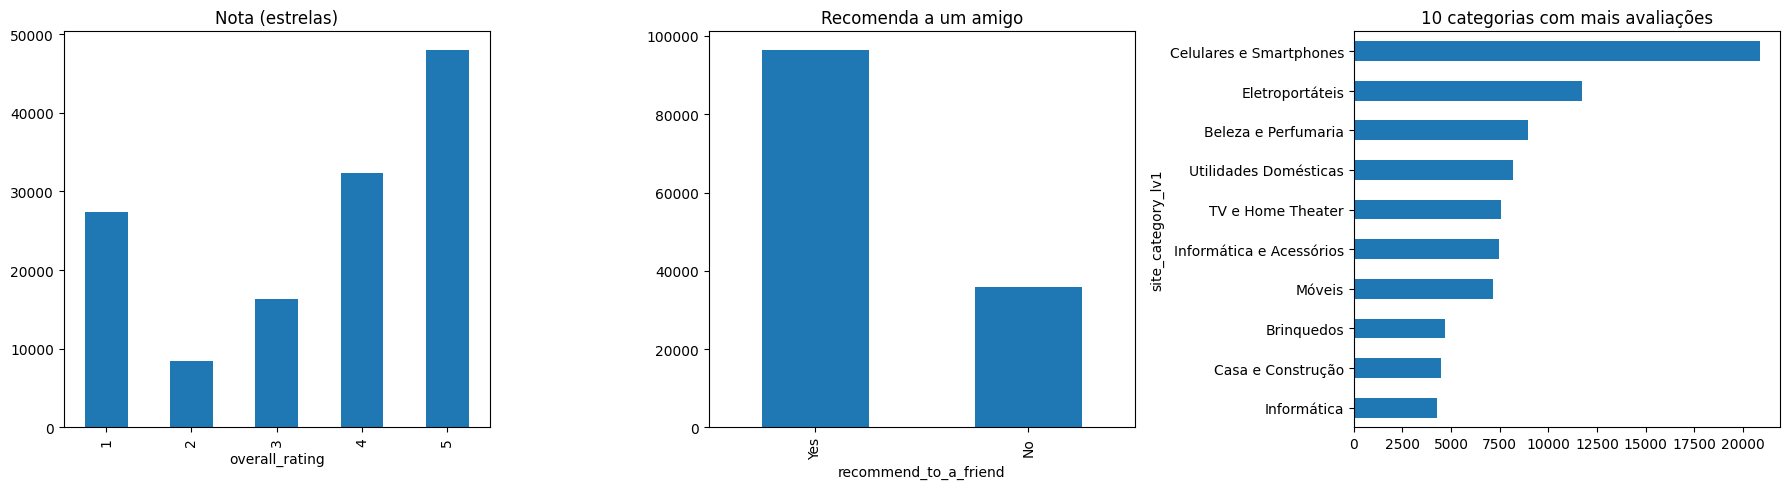

site_category_lv1
Celulares e Smartphones     15.8
Eletroportáteis              8.9
Beleza e Perfumaria          6.8
Utilidades Domésticas        6.2
TV e Home Theater            5.7
Informática e Acessórios     5.6
Móveis                       5.4
Brinquedos                   3.6
Casa e Construção            3.4
Informática                  3.2
Name: proportion, dtype: float64


In [23]:
# [C01.23]
fig, eixos = plt.subplots(1, 3, figsize=(18, 5))

df["overall_rating"].value_counts().sort_index().plot(kind="bar", ax=eixos[0], title="Nota (estrelas)")
df["recommend_to_a_friend"].value_counts().plot(kind="bar", ax=eixos[1], title="Recomenda a um amigo")
df["site_category_lv1"].value_counts().head(10).plot(kind="barh", ax=eixos[2], title="10 categorias com mais avaliações")
eixos[2].invert_yaxis()

plt.tight_layout()
plt.show()

print((df["site_category_lv1"].value_counts(normalize=True).head(10) * 100).round(1))

Os gráficos da nota e da recomendação confirmam o que foi medido nos fatos 1 e 2. A maioria das avaliações é positiva, há muitas avaliações de 1 estrela e poucas de 2 e 3, e há cerca de três "Yes" por cada "No". Nas categorias, a base tem 54 categorias no nível 1. Por serem muitas, o gráfico mostra apenas as 10 com mais avaliações, para que continue legível. A base está concentrada em poucas categorias. Celulares e Smartphones sozinha reúne 15,8% das avaliações, seguida de Eletroportáteis (8,9%) e Beleza e Perfumaria (6,8%). O classificador vai, por isso, aprender sobretudo com avaliações destas categorias, e os resultados podem ser menos fiáveis nas categorias pequenas. Nota-se também que produtos semelhantes aparecem em categorias separadas, como "Informática" e "Informática e Acessórios", o que deve ser tido em conta na análise por categoria.

## Faltantes por coluna

In [24]:
# [C01.24]
faltas = df.isna().sum().sort_values(ascending=False)
pd.DataFrame({"em_falta": faltas, "percentagem": (faltas / len(df) * 100).round(1)})

,em_falta,percentagem
product_brand,91391,69.0
reviewer_birth_year,5984,4.5
reviewer_gender,4136,3.1
site_category_lv2,4013,3.0
reviewer_state,3991,3.0
review_text,3275,2.5
review_title,302,0.2
product_name,84,0.1
recommend_to_a_friend,18,0.0
site_category_lv1,6,0.0


Das 14 colunas, 10 têm valores em falta. Como o rótulo é recommend_to_a_friend, removemos as 18 avaliações sem recomendação e as 3.275 sem texto, porque sem rótulo ou sem texto não podem ser usadas pelo classificador, o que deixa 129.080 avaliações. Os 302 títulos em falta são tratados como texto vazio, já que o título só é usado no teste de vazamento. As 6 avaliações sem categoria de nível 1 ficam fora apenas da análise por categoria. A marca, o nome do produto e a categoria de nível 2 não são usados. O ano de nascimento, o género e o estado do avaliador só são usados em análise agregada, excluindo as linhas em falta.

## Decisão do rótulo

In [25]:
# [C01.25]
base = df.dropna(subset=["review_text", "recommend_to_a_friend"]).copy()
base["classe"] = base["recommend_to_a_friend"]

print("Número de classes:", base["classe"].nunique())
print(base["classe"].value_counts())
print()

tres = base[base["overall_rating"] == 3]
print("Avaliações de 3 estrelas:", len(tres))
print((tres["classe"].value_counts(normalize=True) * 100).round(1))

Número de classes: 2
classe
Yes    95066
No     34014
Name: count, dtype: int64

Avaliações de 3 estrelas: 16008
classe
Yes    88.6
No     11.4
Name: proportion, dtype: float64


O rótulo escolhido pela nossa equipe foi "recommend_to_a_friend", com duas classes, "Yes" (95.066 avaliações) e "No" (34.014). As 16.008 avaliações de 3 estrelas mantêm-se na base e ficam com a resposta que o próprio cliente deu à pergunta "recomendaria a um amigo?", o que coloca 88,6% delas em "Yes" e 11,4% em "No". A decisão justifica-se por este número, próximo dos 88,5% medidos na base toda, porque mostra que as 3 estrelas não são neutras para o cliente, e a recomendação capta essa avaliação de forma mais fiel do que uma classe neutra. Fora das 3 estrelas, os dois rótulos discordam pouco, com apenas 2.863 avaliações de 1 ou 2 estrelas que recomendam e 1.213 de 4 ou 5 estrelas que não recomendam.

## Baseline da classe maioritária

In [26]:
# [C01.26]
rotulo = df.dropna(subset=["review_text", "recommend_to_a_friend"])["recommend_to_a_friend"]
BASELINE = rotulo.value_counts(normalize=True).max()
print("Baseline guardado:", round(BASELINE, 3))

Baseline guardado: 0.736


O valor medido na pergunta 4, de 0,736, fica guardado na variável BASELINE e será apresentado ao lado de toda a acurácia do projeto, já que uma acurácia só tem valor se for claramente superior a ele.